<div style="background:linear-gradient(90deg,#4A2F85,#A98BDB);padding:22px 28px;border-radius:14px">
<h1 style="color:#FFFFFF;margin:0">Práctica 3b · Procesamiento de imágenes</h1>
<p style="color:#E8DEF8;margin:6px 0 0 0">Procesamiento de Imágenes, Audio y Vídeo</p>
</div>



**Ficheros que genera**

| Ejercicio | Fichero |
|---|---|
| 1 | `vídeo2.mp4` |
| 2 | `captura_rango_dinamico.png` (opcional, con la tecla `S`) |
| 3 | `video7.mp4` |
| 4 | `imagen3_ecualizada.png` |
| 5 | `video_otsu.mp4` |
| 6 | `imagen3_salida.png` |


In [1]:
# ============================================================
#  Configuración general, utilidades y estilo (paleta lila)
# ============================================================
import os
import functools
import numpy as np
import cv2 as cv
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image, ImageDraw, ImageFont

print('OpenCV', cv.__version__, '| NumPy', np.__version__, '| Matplotlib', mpl.__version__)

# ---------- Paleta lila (hex RGB) ----------
LILA = {
    'fondo':    '#F5F0FC',   # fondo general
    'tarjeta':  '#FFFFFF',
    'claro':    '#E8DEF8',
    'suave':    '#CDBBEA',
    'medio':    '#A98BDB',
    'primario': '#7B54C7',
    'oscuro':   '#4A2F85',
    'tinta':    '#2D1B4E',   # texto
    'gris':     '#7A6A99',   # texto secundario
}

def bgr(hex_color):
    """'#RRGGBB' -> (B, G, R), que es el orden que usa OpenCV."""
    h = hex_color.lstrip('#')
    r, g, b = int(h[0:2], 16), int(h[2:4], 16), int(h[4:6], 16)
    return (b, g, r)

# ---------- Estilo de Matplotlib ----------
mpl.rcParams.update({
    'figure.facecolor': LILA['fondo'], 'savefig.facecolor': LILA['fondo'],
    'axes.facecolor': LILA['tarjeta'], 'axes.edgecolor': LILA['suave'],
    'axes.labelcolor': LILA['tinta'], 'axes.titlecolor': LILA['oscuro'],
    'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'xtick.color': LILA['gris'], 'ytick.color': LILA['gris'],
    'text.color': LILA['tinta'], 'grid.color': LILA['claro'],
    'axes.grid': False, 'legend.frameon': True, 'legend.facecolor': LILA['tarjeta'],
    'legend.edgecolor': LILA['suave'], 'figure.dpi': 110,
    'axes.prop_cycle': mpl.cycler(color=[LILA['primario'], LILA['medio'], LILA['oscuro'], '#D17FC2']),
})
CMAP_LILA = LinearSegmentedColormap.from_list('lila', ['#FFFFFF', LILA['suave'], LILA['primario'], LILA['tinta']])

# ---------- Rutas ----------
# Busca las imágenes de la práctica en la carpeta actual o en las carpetas habituales.
CARPETAS_RECURSOS = ['.', 'recursos', 'PL_03_recursos', 'imagenes', 'images']

def ruta_recurso(nombre):
    for carpeta in CARPETAS_RECURSOS:
        ruta = os.path.join(carpeta, nombre)
        if os.path.isfile(ruta):
            return ruta
    raise FileNotFoundError(
        f"No encuentro '{nombre}'. Colócalo junto al notebook o en una de estas carpetas: {CARPETAS_RECURSOS}")

# ---------- Lectura y escritura de imágenes ----------
# cv.imread / cv.imwrite fallan en Windows si la ruta tiene tildes o 'ñ'; con
# np.fromfile + imdecode (y imencode + tofile) se evita ese problema.
def leer_imagen(nombre, flags=cv.IMREAD_COLOR):
    datos = np.fromfile(ruta_recurso(nombre), dtype=np.uint8)
    img = cv.imdecode(datos, flags)
    if img is None:
        raise ValueError(f"No se pudo decodificar '{nombre}'")
    return img

def guardar_imagen(nombre, imagen):
    ok, buf = cv.imencode(os.path.splitext(nombre)[1], imagen)
    if not ok:
        raise ValueError(f"No se pudo codificar '{nombre}'")
    buf.tofile(nombre)

def a_rgb(imagen):
    """BGR o gris -> RGB para Matplotlib."""
    if imagen.ndim == 2:
        return cv.cvtColor(imagen, cv.COLOR_GRAY2RGB)
    return cv.cvtColor(imagen, cv.COLOR_BGR2RGB)

# ---------- Escritura de vídeo ----------
class EscritorVideo:
    """Escribe un .mp4 fotograma a fotograma (sin guardar todo en memoria).

    Se graba primero con un nombre ASCII y al final se renombra, así funciona
    aunque el nombre final lleve tilde (vídeo2.mp4) o la ruta tenga caracteres raros.
    """
    def __init__(self, nombre, fps, ancho, alto):
        self.nombre, self.fps, self.tam = nombre, fps, (ancho, alto)
        self.tmp = f'_tmp_{os.getpid()}.mp4'
        self.writer = cv.VideoWriter(self.tmp, cv.VideoWriter_fourcc(*'mp4v'), fps, self.tam)
        if not self.writer.isOpened():
            raise RuntimeError('OpenCV no ha podido abrir el VideoWriter (codec mp4v).')
        self.fotogramas = 0

    def escribir(self, frame):
        if frame.ndim == 2:
            frame = cv.cvtColor(frame, cv.COLOR_GRAY2BGR)
        assert (frame.shape[1], frame.shape[0]) == self.tam, 'Tamaño de fotograma incorrecto'
        self.writer.write(frame)
        self.fotogramas += 1

    def __enter__(self):
        return self

    def __exit__(self, tipo, valor, traza):
        self.writer.release()
        if tipo is None:
            os.replace(self.tmp, self.nombre)
        elif os.path.exists(self.tmp):
            os.remove(self.tmp)

def resumen_video(nombre):
    """Reabre el vídeo y comprueba lo que se ha guardado."""
    cap = cv.VideoCapture(nombre)
    n = int(cap.get(cv.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv.CAP_PROP_FPS)
    ancho, alto = int(cap.get(cv.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    kb = os.path.getsize(nombre) / 1024
    print(f"'{nombre}' -> {n} fotogramas | {ancho}x{alto} | {fps:.0f} fps | {n / fps:.1f} s | {kb:,.0f} KB")
    return n

def fotogramas_de_video(nombre, indices):
    """Lee del vídeo guardado los fotogramas indicados (para las vistas previas)."""
    cap = cv.VideoCapture(nombre)
    salida = []
    for i in indices:
        cap.set(cv.CAP_PROP_POS_FRAMES, i)
        ok, frame = cap.read()
        salida.append(frame if ok else None)
    cap.release()
    return salida

# ---------- Texto con tildes sobre imágenes de OpenCV ----------
# cv.putText no sabe dibujar tildes ni 'ñ'; con Pillow y la fuente DejaVu (que
# trae Matplotlib) se dibujan bien.
_FUENTE = os.path.join(mpl.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf')
_FUENTE_B = os.path.join(mpl.get_data_path(), 'fonts', 'ttf', 'DejaVuSans-Bold.ttf')

@functools.lru_cache(maxsize=None)
def _fuente(tam, negrita):
    return ImageFont.truetype(_FUENTE_B if negrita else _FUENTE, tam)

def escribir_textos(img, textos):
    """Dibuja una lista de textos sobre `img` (BGR, se modifica en su sitio).

    Cada texto es (cadena, (x, y), tamaño_px, color_hex, negrita, ancla), con
    ancla 'l' (izquierda), 'm' (centro) o 'r' (derecha) respecto a x.
    """
    pil = Image.fromarray(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    dib = ImageDraw.Draw(pil)
    for cadena, pos, tam, color, negrita, ancla in textos:
        dib.text(pos, cadena, font=_fuente(tam, negrita), fill=color, anchor=ancla + 'm')
    img[:] = cv.cvtColor(np.asarray(pil), cv.COLOR_RGB2BGR)

def medir_texto(cadena, tam, negrita=False):
    return _fuente(tam, negrita).getlength(cadena)

# ---------- Formas con esquinas redondeadas ----------
def rect_redondeado(img, p1, p2, color, radio=14, alfa=1.0):
    """Rectángulo relleno con esquinas redondeadas (color en hex)."""
    (x1, y1), (x2, y2) = p1, p2
    capa = img.copy() if alfa < 1.0 else img
    c = bgr(color)
    cv.rectangle(capa, (x1 + radio, y1), (x2 - radio, y2), c, -1, cv.LINE_AA)
    cv.rectangle(capa, (x1, y1 + radio), (x2, y2 - radio), c, -1, cv.LINE_AA)
    for cx, cy in ((x1 + radio, y1 + radio), (x2 - radio, y1 + radio),
                   (x1 + radio, y2 - radio), (x2 - radio, y2 - radio)):
        cv.circle(capa, (cx, cy), radio, c, -1, cv.LINE_AA)
    if alfa < 1.0:
        cv.addWeighted(capa, alfa, img, 1 - alfa, 0, img)

def degradado_horizontal(ancho, alto, color_izq, color_der):
    izq, der = np.array(bgr(color_izq), float), np.array(bgr(color_der), float)
    t = np.linspace(0, 1, ancho)[None, :, None]
    fila = izq * (1 - t) + der * t
    return np.repeat(fila, alto, axis=0).astype(np.uint8)

def mostrar(imagenes, titulos, columnas=None, figsize=None, suptitulo=None):
    """Cuadrícula de imágenes con títulos (acepta BGR o gris)."""
    n = len(imagenes)
    columnas = columnas or n
    filas = int(np.ceil(n / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=figsize or (4.2 * columnas, 3.6 * filas))
    for ax in np.atleast_1d(ejes).ravel():
        ax.axis('off')
    for ax, im, t in zip(np.atleast_1d(ejes).ravel(), imagenes, titulos):
        ax.imshow(a_rgb(im))
        ax.set_title(t)
    if suptitulo:
        fig.suptitle(suptitulo, fontsize=13, fontweight='bold', color=LILA['oscuro'])
    fig.tight_layout()
    plt.show()

print('Utilidades cargadas.')


OpenCV 5.0.0 | NumPy 1.26.4 | Matplotlib 3.9.2
Utilidades cargadas.


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 1 · Negativo y vídeo por columnas</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>


**Qué se pide.** Calcular el negativo de `imagen2.png` (`255 - imagen(i, j)`) y crear un vídeo en el que aparezca primero el negativo y la imagen original vaya entrando columna a columna. El número de iteraciones es igual al ancho de la imagen y el resultado se guarda como `vídeo2.mp4`.

**Solución.**

- El vídeo parte del negativo y en la iteración `k` se copia la columna `k` de la imagen original. Así la original avanza una columna hacia la derecha por fotograma y el último fotograma es la imagen completa.
- Hay un fotograma por columna (768 en esta imagen). A 60 fps dura unos 13 s.
- Los fotogramas se escriben uno a uno, sin guardarlos todos en memoria.


In [2]:
# ---------- Ejercicio 1: negativo + vídeo por columnas ----------
NOMBRE_VIDEO_1 = 'vídeo2.mp4'
FPS_1 = 60

imagen = leer_imagen('imagen2.png')
negativo = 255 - imagen                     # negativo: 255 - imagen(i, j)
alto, ancho = imagen.shape[:2]

# El vídeo tiene tantos fotogramas como columnas. En cada iteración la imagen
# original avanza una columna hacia la derecha sobre el negativo.
with EscritorVideo(NOMBRE_VIDEO_1, FPS_1, ancho, alto) as video:
    frame = negativo.copy()
    for k in range(ancho):
        frame[:, k] = imagen[:, k]          # columna k: de negativo a original
        video.escribir(frame)

n_frames = resumen_video(NOMBRE_VIDEO_1)
assert n_frames == ancho, 'El número de iteraciones debe ser igual al ancho de la imagen'


'vídeo2.mp4' -> 768 fotogramas | 768x512 | 60 fps | 12.8 s | 7,584 KB


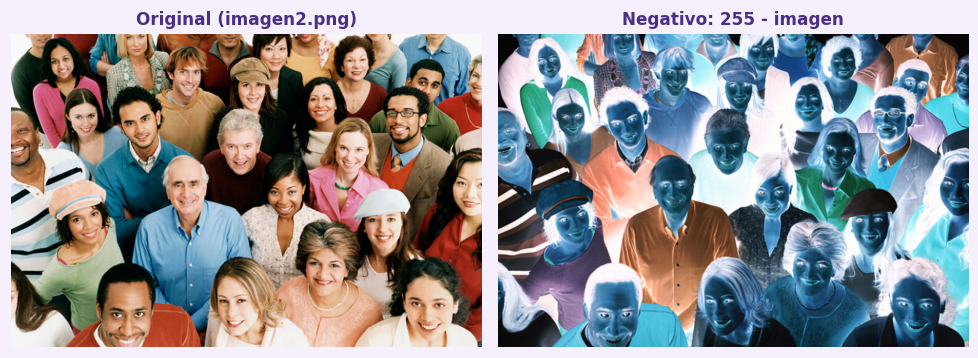

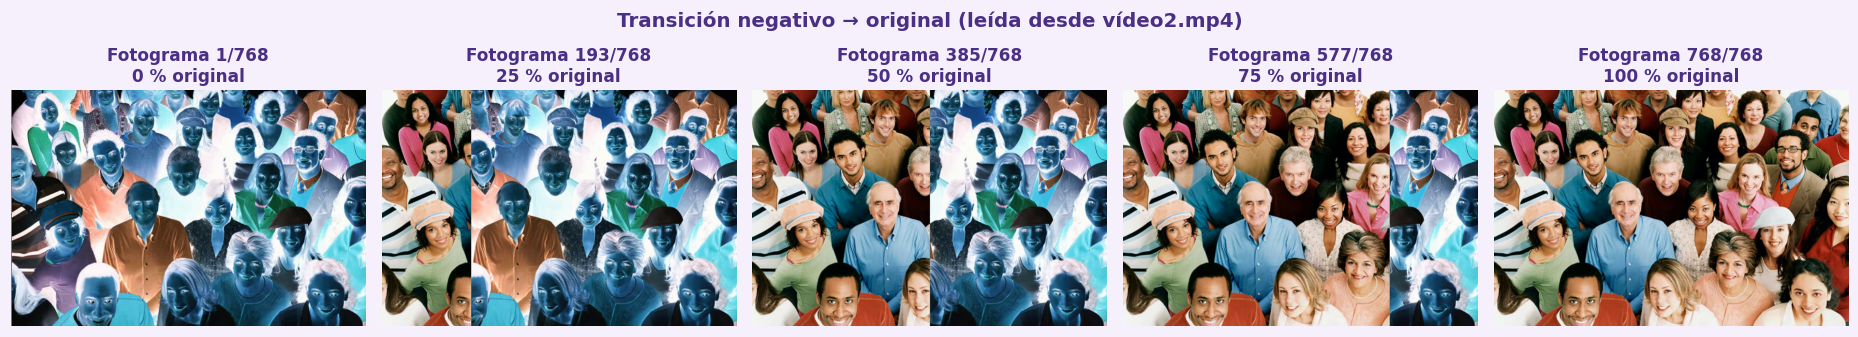

PSNR último fotograma vs original: 34.3 dB


In [3]:
# Vista previa: imagen, negativo y fotogramas del vídeo ya guardado
mostrar([imagen, negativo], ['Original (imagen2.png)', 'Negativo: 255 - imagen'], figsize=(9, 3.6))

indices = [0, ancho // 4, ancho // 2, 3 * ancho // 4, ancho - 1]
frames = fotogramas_de_video(NOMBRE_VIDEO_1, indices)
titulos = [f'Fotograma {i + 1}/{ancho}\n{100 * (i + 1) / ancho:.0f} % original' for i in indices]
mostrar(frames, titulos, figsize=(17, 3.4), suptitulo='Transición negativo → original (leída desde vídeo2.mp4)')

# Comprobación: el último fotograma coincide con la imagen original (salvo pérdida del códec)
print(f'PSNR último fotograma vs original: {cv.PSNR(frames[-1], imagen):.1f} dB')


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 2 · Rango dinámico con trackbars</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>


**Qué se pide.** Una aplicación con trackbars para aplicar las transformaciones logarítmica y exponencial del rango dinámico, eligiendo la intensidad de la compresión o la expansión, con dos imágenes en las que se vea bien el efecto de ambas.

**Transformaciones.** Con $r$ la intensidad de entrada y $s$ la de salida:

$$s = c\,\log\!\big[1 + (e^{\sigma}-1)\,r\big] \qquad s = c\,\big[(1+\alpha)^{r} - 1\big] \qquad c = \frac{L-1}{\log(1 + r_{\max})}$$

- $\sigma$ controla la compresión logarítmica y $\alpha$ la expansión exponencial. $L = 256$ y $r_{\max}$ es la intensidad máxima de la imagen.
- Como son operadores puntuales, cada transformación se calcula una vez para los 256 valores posibles (tabla `cv.LUT`) y se aplica a toda la imagen. Esa misma tabla es la curva que se dibuja en la interfaz.

**Imágenes elegidas.** `imagen3.png`, muy oscura (la logarítmica la aclara mucho), e `imagen7_2.png`, clara (la exponencial separa las zonas brillantes y oscurece el resto). Las dos transformaciones se aplican siempre a la imagen elegida, así se ve también el efecto contrario.

**Controles.**

| Barra | Rango | Efecto |
|---|---|---|
| `Imagen` | 0 – 1 | cambia entre las dos imágenes |
| `Sigma x100` | 1 – 100 | $\sigma$ de 0.01 a 1.00 (inicio 0.50) |
| `Alfa x10000` | 0 – 100 | $\alpha$ de 0 a 0.0100 (inicio 0.0070) |



In [4]:
# ---------- Ejercicio 2: rango dinámico (logarítmica y exponencial) ----------
L = 256                                       # niveles de intensidad (imágenes de 8 bits)
IMAGENES_EJ2 = ['imagen3.png', 'imagen7_2.png']   # una oscura (log) y una clara (exp)
SIGMA_INI, ALFA_INI = 0.50, 0.007             # valores de partida (los de las diapositivas)

def factor_escala(r_max):
    """c = (L - 1) / log(1 + r_max)"""
    return (L - 1) / np.log(1 + max(int(r_max), 1))

def lut_logaritmica(sigma, r_max):
    """Compresión logarítmica: s = c * log[1 + (e^sigma - 1) * r]"""
    r = np.arange(L, dtype=np.float64)
    s = factor_escala(r_max) * np.log1p(np.expm1(sigma) * r)
    return np.clip(np.rint(s), 0, L - 1).astype(np.uint8)

def lut_exponencial(alfa, r_max):
    """Expansión exponencial: s = c * [(1 + alfa)^r - 1]"""
    r = np.arange(L, dtype=np.float64)
    s = factor_escala(r_max) * (np.power(1.0 + alfa, r) - 1.0)
    return np.clip(np.rint(s), 0, L - 1).astype(np.uint8)

# ---------- Diseño de la interfaz ----------
ANCHO_PANEL, ALTO_TARJETA, MARGEN = 340, 528, 24
ANCHO_LIENZO, ALTO_LIENZO = 3 * ANCHO_PANEL + 4 * MARGEN, 650
Y_TARJETA = 84
CAJA_IMG = (316, 300)                         # (ancho, alto) del recuadro de imagen
ALTO_CURVA = 120

def _x_tarjeta(i):
    return MARGEN + i * (ANCHO_PANEL + MARGEN)

@functools.lru_cache(maxsize=1)
def _fondo_estatico():
    """Cabecera, tarjetas y textos fijos (se construye una sola vez)."""
    lienzo = np.full((ALTO_LIENZO, ANCHO_LIENZO, 3), bgr(LILA['fondo']), np.uint8)
    lienzo[:64] = degradado_horizontal(ANCHO_LIENZO, 64, LILA['oscuro'], LILA['medio'])
    # sombras suaves de las tarjetas
    sombra = np.zeros_like(lienzo)
    for i in range(3):
        x = _x_tarjeta(i)
        rect_redondeado(sombra, (x + 2, Y_TARJETA + 6), (x + ANCHO_PANEL + 2, Y_TARJETA + ALTO_TARJETA + 6), '#FFFFFF', 18)
    sombra = cv.GaussianBlur(sombra, (0, 0), 7)
    mascara = (sombra[..., :1] / 255.0)
    lienzo = (lienzo * (1 - 0.22 * mascara) + np.array(bgr(LILA['medio'])) * 0.22 * mascara).astype(np.uint8)
    for i in range(3):
        x = _x_tarjeta(i)
        rect_redondeado(lienzo, (x, Y_TARJETA), (x + ANCHO_PANEL, Y_TARJETA + ALTO_TARJETA), LILA['tarjeta'], 18)
    titulos = [('Original', 'imagen de entrada'),
               ('Compresión logarítmica', 's = c · log[1 + (e^σ − 1) · r]'),
               ('Expansión exponencial', 's = c · [(1 + α)^r − 1]')]
    textos = [('Transformaciones del rango dinámico', (MARGEN, 24), 24, '#FFFFFF', True, 'l'),
              ('Compresión logarítmica y expansión exponencial · Práctica 3 · PIAV', (MARGEN, 48), 12, LILA['claro'], False, 'l'),
              ('ESC / Q: salir     ·     S: guardar captura     ·     barras inferiores: imagen, σ (×100) y α (×10000)',
               (ANCHO_LIENZO // 2, 632), 12, LILA['gris'], False, 'm')]
    for i, (t, sub) in enumerate(titulos):
        cx = _x_tarjeta(i) + ANCHO_PANEL // 2
        textos.append((t, (cx, Y_TARJETA + 24), 16, LILA['oscuro'], True, 'm'))
        textos.append((sub, (cx, Y_TARJETA + 46), 12, LILA['gris'], False, 'm'))
    escribir_textos(lienzo, textos)
    return lienzo

# ---------- Datos de cada imagen (se calculan una vez) ----------
def _preparar(nombre):
    original = leer_imagen(nombre, cv.IMREAD_UNCHANGED)
    if original.ndim == 3 and original.shape[2] == 4:
        original = original[..., :3]
    if original.ndim == 2:
        original = cv.cvtColor(original, cv.COLOR_GRAY2BGR)
    gris = cv.cvtColor(original, cv.COLOR_BGR2GRAY)
    hist = cv.calcHist([gris], [0], None, [L], [0, L]).ravel()
    ancho_caja, alto_caja = CAJA_IMG
    esc = min(ancho_caja / original.shape[1], alto_caja / original.shape[0])
    tam = (max(1, round(original.shape[1] * esc)), max(1, round(original.shape[0] * esc)))
    mini = cv.resize(original, tam, interpolation=cv.INTER_AREA if esc < 1 else cv.INTER_LINEAR)
    return {'nombre': nombre, 'r_max': int(original.max()), 'hist': np.sqrt(hist / hist.max()),
            'mini': mini, 'media': float(original.mean())}

DATOS_EJ2 = [_preparar(n) for n in IMAGENES_EJ2]

# ---------- Elementos dibujados con OpenCV ----------
def _pegar_imagen(lienzo, x_tarjeta, mini):
    x0, y0 = x_tarjeta + 12, Y_TARJETA + 62
    rect_redondeado(lienzo, (x0, y0), (x0 + CAJA_IMG[0], y0 + CAJA_IMG[1]), LILA['claro'], 10)
    h, w = mini.shape[:2]
    ox, oy = x0 + (CAJA_IMG[0] - w) // 2, y0 + (CAJA_IMG[1] - h) // 2
    lienzo[oy:oy + h, ox:ox + w] = mini

def _dibujar_curva(lienzo, x_tarjeta, hist, lut, textos):
    """Caja con el histograma de entrada y, encima, la curva de transferencia."""
    x0, y0, w, h = x_tarjeta + 12, Y_TARJETA + 374, 316, ALTO_CURVA
    rect_redondeado(lienzo, (x0, y0), (x0 + w, y0 + h), LILA['fondo'], 10)
    ax0, ax1, ay0, ay1 = x0 + 14, x0 + w - 14, y0 + 10, y0 + h - 22

    def px(r): return ax0 + r / 255.0 * (ax1 - ax0)
    def py(s): return ay1 - s / 255.0 * (ay1 - ay0)

    for v in (0, 64, 128, 192, 255):                            # rejilla
        cv.line(lienzo, (round(px(v)), ay0), (round(px(v)), ay1), bgr(LILA['claro']), 1, cv.LINE_AA)
        cv.line(lienzo, (ax0, round(py(v))), (ax1, round(py(v))), bgr(LILA['claro']), 1, cv.LINE_AA)
    # histograma de la imagen de entrada (sobre el eje r)
    silueta = [(round(px(0)), ay1)] + [(round(px(i)), round(ay1 - hist[i] * (ay1 - ay0) * 0.95)) for i in range(L)] + [(round(px(255)), ay1)]
    capa = lienzo.copy()
    cv.fillPoly(capa, [np.array(silueta, np.int32)], bgr(LILA['suave']), cv.LINE_AA)
    cv.addWeighted(capa, 0.75, lienzo, 0.25, 0, lienzo)
    if lut is not None:
        for t in np.linspace(0, 1, 28):                         # identidad s = r (discontinua)
            if int(t * 27) % 2 == 0:
                a, b = t * 255, min(255, (t + 1 / 27) * 255)
                cv.line(lienzo, (round(px(a)), round(py(a))), (round(px(b)), round(py(b))), bgr(LILA['medio']), 1, cv.LINE_AA)
        pts = np.array([(px(i), py(int(lut[i]))) for i in range(L)], np.float32)
        cv.polylines(lienzo, [np.round(pts).astype(np.int32)], False, bgr(LILA['primario']), 2, cv.LINE_AA)
        textos.append(('s', (ax0 + 6, ay0 + 6), 11, LILA['oscuro'], True, 'l'))
    cv.rectangle(lienzo, (ax0, ay0), (ax1, ay1), bgr(LILA['suave']), 1, cv.LINE_AA)
    textos += [('0', (ax0, ay1 + 11), 11, LILA['gris'], False, 'm'),
               ('255', (ax1, ay1 + 11), 11, LILA['gris'], False, 'm'),
               ('r (intensidad de entrada)', ((ax0 + ax1) // 2, ay1 + 11), 11, LILA['gris'], False, 'm')]

def renderizar(idx, sigma, alfa):
    """Devuelve el lienzo BGR completo para la imagen idx y los parámetros dados."""
    d = DATOS_EJ2[idx]
    lienzo = _fondo_estatico().copy()
    lut_log, lut_exp = lut_logaritmica(sigma, d['r_max']), lut_exponencial(alfa, d['r_max'])
    imagenes = [d['mini'], cv.LUT(d['mini'], lut_log), cv.LUT(d['mini'], lut_exp)]
    luts = [None, lut_log, lut_exp]
    c = factor_escala(d['r_max'])
    infos = [f"r_max = {d['r_max']}   ·   media = {d['media']:.1f}",
             f"σ = {sigma:.2f}   ·   c = {c:.1f}   ·   media = {imagenes[1].mean():.1f}",
             f"α = {alfa:.4f}   ·   c = {c:.1f}   ·   media = {imagenes[2].mean():.1f}"]
    textos = []
    for i in range(3):
        x = _x_tarjeta(i)
        _pegar_imagen(lienzo, x, imagenes[i])
        _dibujar_curva(lienzo, x, d['hist'], luts[i], textos)
        textos.append((infos[i], (x + ANCHO_PANEL // 2, Y_TARJETA + 510), 12, LILA['tinta'], False, 'm'))
    # etiqueta con el nombre de la imagen actual, en la cabecera
    nombre = d['nombre']
    ancho_pildora = int(medir_texto(nombre, 14, True)) + 28
    rect_redondeado(lienzo, (ANCHO_LIENZO - MARGEN - ancho_pildora, 17), (ANCHO_LIENZO - MARGEN, 47), LILA['claro'], 15)
    textos.append((nombre, (ANCHO_LIENZO - MARGEN - ancho_pildora // 2, 32), 14, LILA['oscuro'], True, 'm'))
    escribir_textos(lienzo, textos)
    return lienzo

# ---------- Aplicación interactiva (trackbars) ----------
def lanzar_app_rango_dinamico():
    ventana = 'Rango dinamico'                # nombre ASCII: HighGUI no maneja bien las tildes
    cv.namedWindow(ventana, cv.WINDOW_AUTOSIZE)
    nada = lambda v: None
    cv.createTrackbar('Imagen', ventana, 0, len(DATOS_EJ2) - 1, nada)
    cv.createTrackbar('Sigma x100', ventana, round(SIGMA_INI * 100), 100, nada)
    cv.createTrackbar('Alfa x10000', ventana, round(ALFA_INI * 10000), 100, nada)

    anterior, lienzo = None, None
    while True:
        idx = cv.getTrackbarPos('Imagen', ventana)
        sigma = max(cv.getTrackbarPos('Sigma x100', ventana), 1) / 100.0      # sigma en (0, 1]
        alfa = cv.getTrackbarPos('Alfa x10000', ventana) / 10000.0            # alfa en [0, 0.01]
        if (idx, sigma, alfa) != anterior:
            lienzo = renderizar(idx, sigma, alfa)
            cv.imshow(ventana, lienzo)
            anterior = (idx, sigma, alfa)
        tecla = cv.waitKey(30) & 0xFF
        if tecla in (27, ord('q'), ord('Q')):
            break
        if tecla in (ord('s'), ord('S')):
            guardar_imagen('captura_rango_dinamico.png', lienzo)
            print('Captura guardada en captura_rango_dinamico.png')
        if cv.getWindowProperty(ventana, cv.WND_PROP_VISIBLE) < 1:            # cerrada con la X
            break
    cv.destroyAllWindows()
    cv.waitKey(1)

print('Aplicación lista. Ejecuta la siguiente celda para abrirla.')


Aplicación lista. Ejecuta la siguiente celda para abrirla.


**Vista previa de la interfaz**:


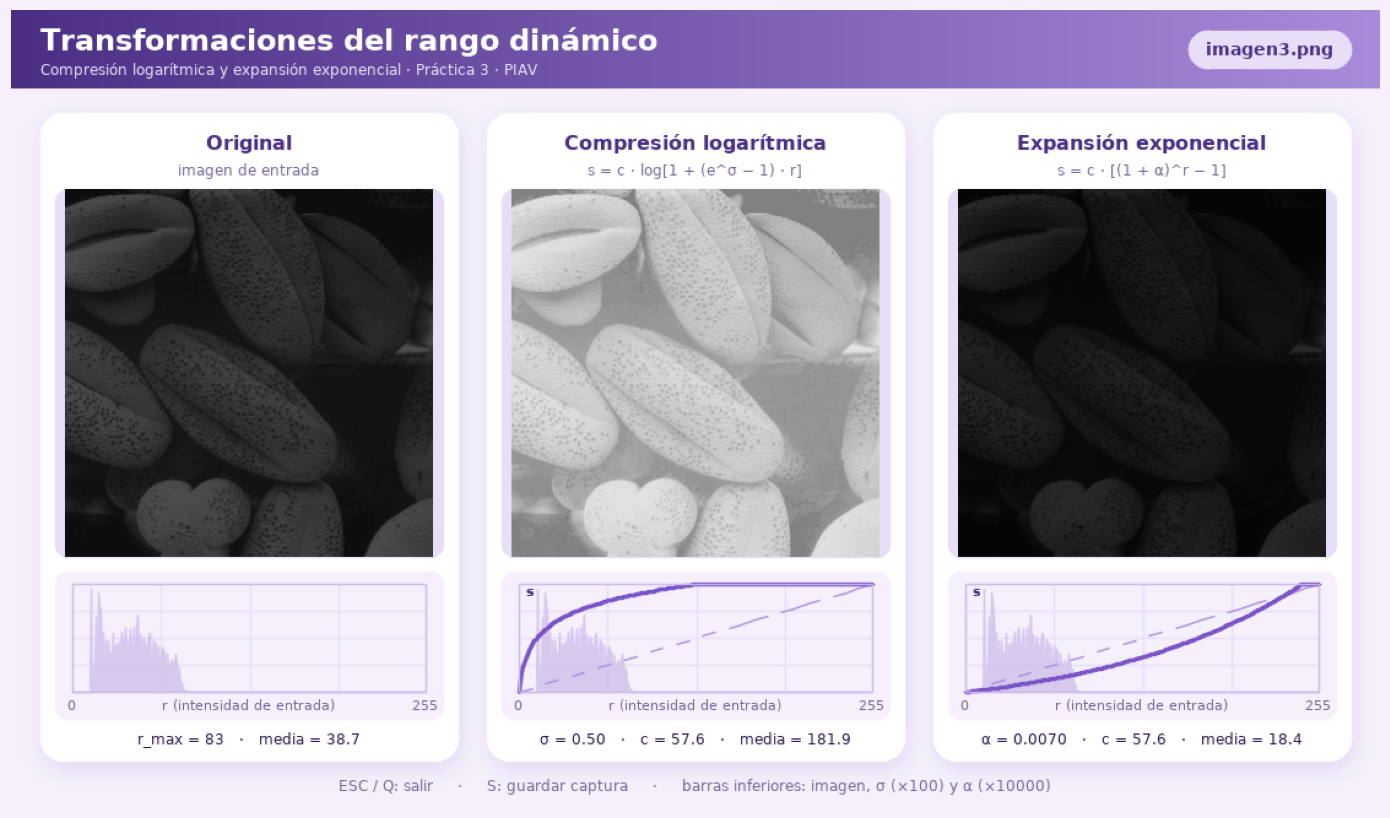

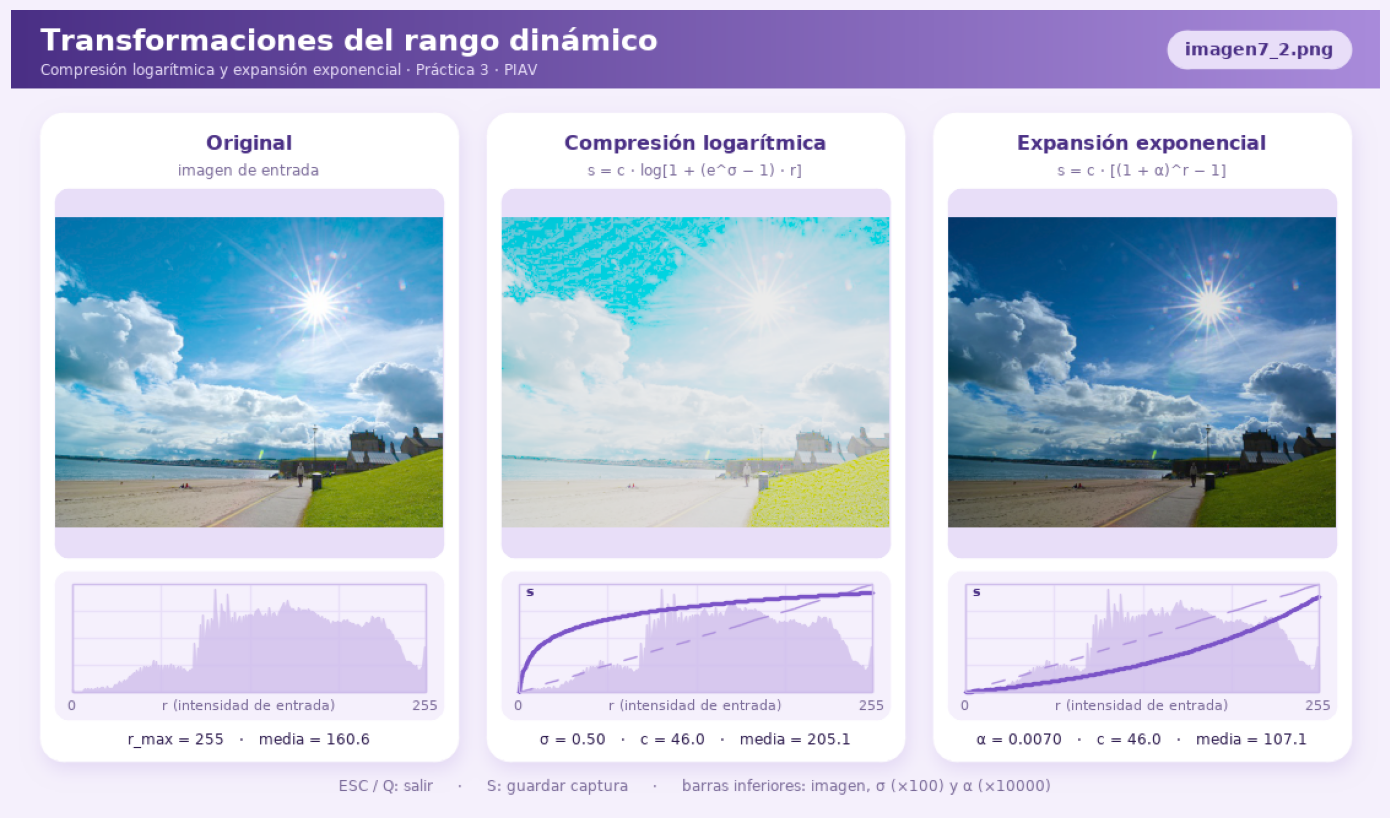

In [5]:
# Vista previa de la interfaz (sin abrir ventana): una captura por imagen
for idx in range(len(DATOS_EJ2)):
    fig = plt.figure(figsize=(12.5, 7.3))
    plt.imshow(a_rgb(renderizar(idx, SIGMA_INI, ALFA_INI)))
    plt.axis('off')
    plt.tight_layout(pad=0.2)
    plt.show()


**Abrir la aplicación**:


In [6]:
# Abre la aplicación (ESC o Q para cerrar; S guarda una captura)
lanzar_app_rango_dinamico()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 3 · Mezcla no lineal de dos imágenes</span><span style="float:right;color:#7A6A99">1.0 puntos</span></div>


**Qué se pide.** Mezclar `imagen7_1.jpg` e `imagen7_2.png` con

$$I_3 = \frac{1+\cos\!\left(\frac{\alpha}{180}\pi\right)}{2}\, I_1 + \frac{1-\cos\!\left(\frac{\alpha}{180}\pi\right)}{2}\, I_2$$

y crear un vídeo de 360 fotogramas subiendo el ángulo 1° por iteración, guardado como `video7.mp4`.

**Solución.**

- Los dos pesos suman siempre 1, así que es una interpolación entre las dos imágenes, pero con un perfil de coseno: la transición empieza y acaba suave en lugar de ir a velocidad constante.
- El ángulo va de 0° a 359°. El primer fotograma es solo `imagen7_1` y el 180° solo `imagen7_2`; el siguiente al 359° volvería a ser el primero, así que el vídeo encaja si se reproduce en bucle.
- Cada fotograma se calcula con `cv.addWeighted`, que ya satura y redondea a 8 bits. A 30 fps dura 12 s.


In [7]:
# ---------- Ejercicio 3: mezcla no lineal de dos imágenes ----------
NOMBRE_VIDEO_3 = 'video7.mp4'
FPS_3 = 30
N_FRAMES_3 = 360                              # 360 fotogramas, +1° por iteración

imagen_1 = leer_imagen('imagen7_1.jpg')
imagen_2 = leer_imagen('imagen7_2.png')
if imagen_1.shape != imagen_2.shape:          # por si las dos imágenes no midieran lo mismo
    imagen_2 = cv.resize(imagen_2, (imagen_1.shape[1], imagen_1.shape[0]), interpolation=cv.INTER_AREA)
alto3, ancho3 = imagen_1.shape[:2]

def pesos(angulo_grados):
    """I3 = (1 + cos(a/180·π))/2 · I1 + (1 − cos(a/180·π))/2 · I2"""
    c = np.cos(angulo_grados / 180.0 * np.pi)
    return (1 + c) / 2, (1 - c) / 2

with EscritorVideo(NOMBRE_VIDEO_3, FPS_3, ancho3, alto3) as video:
    for angulo in range(N_FRAMES_3):          # 0°, 1°, ..., 359°
        w1, w2 = pesos(angulo)
        video.escribir(cv.addWeighted(imagen_1, w1, imagen_2, w2, 0))

n_frames = resumen_video(NOMBRE_VIDEO_3)
assert n_frames == N_FRAMES_3


'video7.mp4' -> 360 fotogramas | 500x400 | 30 fps | 12.0 s | 1,351 KB


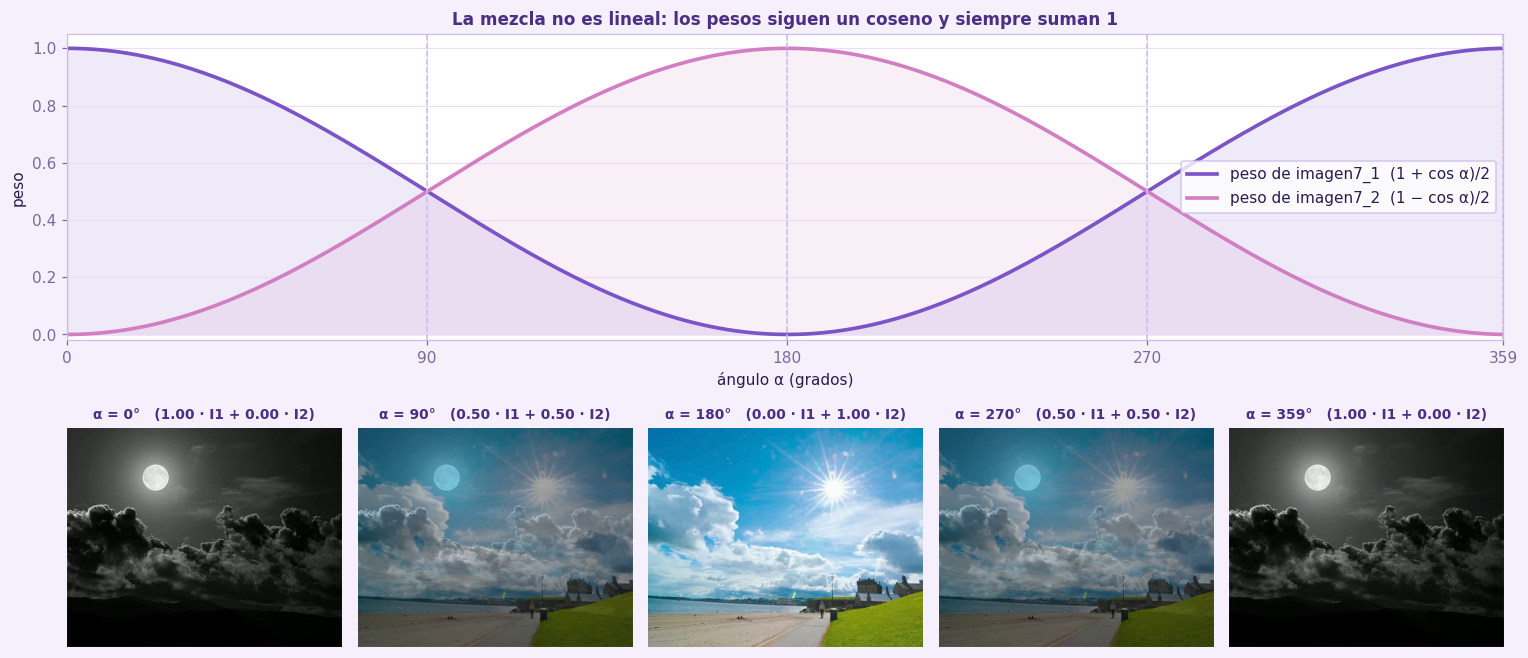

In [8]:
# Vista previa: pesos de la mezcla y fotogramas del vídeo guardado
angulos = np.arange(N_FRAMES_3)
w1, w2 = pesos(angulos)
muestras = [0, 90, 180, 270, 359]
frames = fotogramas_de_video(NOMBRE_VIDEO_3, muestras)

fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(2, 5, height_ratios=[1.25, 1])
ax = fig.add_subplot(gs[0, :])
ax.plot(angulos, w1, lw=2.4, label='peso de imagen7_1  (1 + cos α)/2', color=LILA['primario'])
ax.plot(angulos, w2, lw=2.4, label='peso de imagen7_2  (1 − cos α)/2', color='#D17FC2')
ax.fill_between(angulos, w1, alpha=0.12, color=LILA['primario'])
ax.fill_between(angulos, w2, alpha=0.12, color='#D17FC2')
for a in muestras:
    ax.axvline(a, color=LILA['suave'], lw=1, ls='--')
ax.set_xlim(0, 359); ax.set_ylim(-0.02, 1.05); ax.set_xticks([0, 90, 180, 270, 359])
ax.set_xlabel('ángulo α (grados)'); ax.set_ylabel('peso')
ax.set_title('La mezcla no es lineal: los pesos siguen un coseno y siempre suman 1')
ax.grid(True); ax.legend(loc='center right')
for i, (a, fr) in enumerate(zip(muestras, frames)):
    axi = fig.add_subplot(gs[1, i])
    axi.imshow(a_rgb(fr)); axi.axis('off')
    axi.set_title(f'α = {a}°   ({pesos(a)[0]:.2f} · I1 + {pesos(a)[1]:.2f} · I2)', fontsize=9)
fig.tight_layout(h_pad=2.0)
plt.show()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 4 · Ecualizado del histograma</span><span style="float:right;color:#7A6A99">0.5 puntos</span></div>


**Qué se pide.** Obtener el ecualizado del histograma de `imagen3.png`.

**Solución.** `imagen3.png` es una imagen en grises muy oscura (todos sus valores están entre 13 y 83), así que el ecualizado reparte los niveles por todo el rango. El resultado que se usa después es el de `cv.equalizeHist`. Además he programado a mano los pasos de la teoría (histograma, histograma acumulado, normalización y sustitución de valores) para comprobar que dan lo mismo. En la normalización resto el valor mínimo del acumulado, de modo que el nivel más oscuro pase a 0; sin ese término se obtiene el resultado de la fórmula básica de la diapositiva, que no estira hasta el negro.

El resultado se guarda como `imagen3_ecualizada.png`.


In [9]:
# ---------- Ejercicio 4: ecualizado del histograma de imagen3.png ----------
imagen3 = leer_imagen('imagen3.png', cv.IMREAD_GRAYSCALE)

# Ecualizado con OpenCV (es el resultado que se usa en el ejercicio 6)
imagen3_eq = cv.equalizeHist(imagen3)
guardar_imagen('imagen3_ecualizada.png', imagen3_eq)

# Los mismos cuatro pasos de la teoría, programados a mano, para comprobarlo
def ecualizar_manual(gris):
    h = np.bincount(gris.ravel(), minlength=256)           # 1. histograma h(i)
    H = np.cumsum(h)                                        # 2. histograma acumulado H(i)
    H_min = H[H > 0][0]                                     # 3. normalización a [0, 255]: 255 · H(i) / (w·h),
    H_norm = 255.0 * (H - H_min) / (gris.size - H_min)      #    restando H_min para que el nivel más oscuro pase a 0
    return np.rint(H_norm).astype(np.uint8)[gris]           # 4. g(x) = H*(f(x))

imagen3_eq_manual = ecualizar_manual(imagen3)
dif = np.abs(imagen3_eq.astype(int) - imagen3_eq_manual.astype(int))
print(f'Diferencia máxima entre cv.equalizeHist y la versión manual: {dif.max()} niveles (media {dif.mean():.2f})')
print(f'Rango original:   [{imagen3.min()}, {imagen3.max()}]   media {imagen3.mean():.1f}   desv. típica {imagen3.std():.1f}')
print(f'Rango ecualizado: [{imagen3_eq.min()}, {imagen3_eq.max()}]   media {imagen3_eq.mean():.1f}   desv. típica {imagen3_eq.std():.1f}')


Diferencia máxima entre cv.equalizeHist y la versión manual: 0 niveles (media 0.00)
Rango original:   [13, 83]   media 38.7   desv. típica 17.3
Rango ecualizado: [0, 255]   media 121.5   desv. típica 77.6


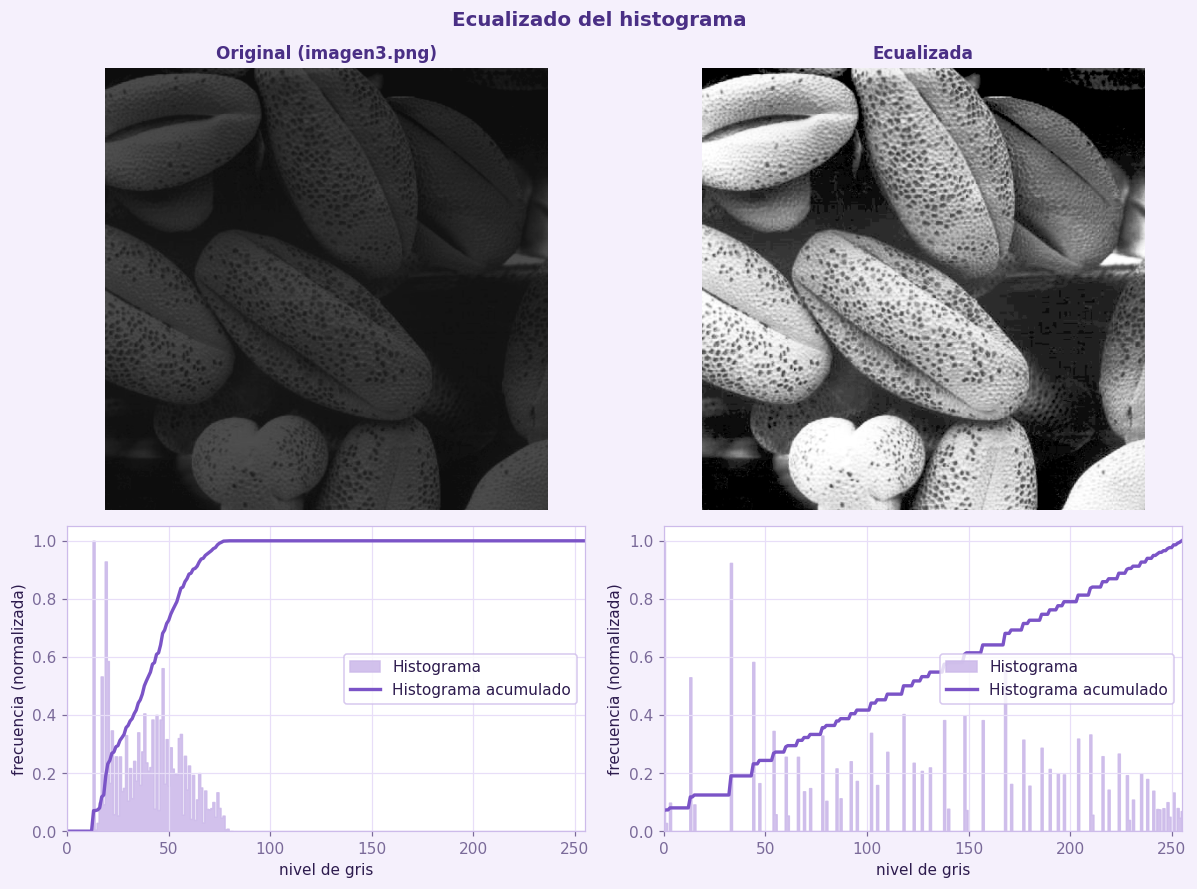

In [10]:
# Imágenes e histogramas (normalizados) antes y después del ecualizado
def histograma(gris):
    h = cv.calcHist([gris], [0], None, [256], [0, 256]).ravel()
    return h / h.max(), np.cumsum(h) / h.sum()

fig, ejes = plt.subplots(2, 2, figsize=(11, 8.2), gridspec_kw={'height_ratios': [1.45, 1]})
for col, (im, titulo) in enumerate([(imagen3, 'Original (imagen3.png)'), (imagen3_eq, 'Ecualizada')]):
    ejes[0, col].imshow(im, cmap='gray', vmin=0, vmax=255)
    ejes[0, col].set_title(titulo); ejes[0, col].axis('off')
    h, acum = histograma(im)
    ax = ejes[1, col]
    ax.fill_between(np.arange(256), h, step='mid', color=LILA['suave'], alpha=0.9, label='Histograma')
    ax.plot(acum, color=LILA['primario'], lw=2.2, label='Histograma acumulado')
    ax.set_xlim(0, 255); ax.set_ylim(0, 1.05); ax.grid(True)
    ax.set_xlabel('nivel de gris'); ax.set_ylabel('frecuencia (normalizada)')
    ax.legend(loc='center right')
fig.suptitle('Ecualizado del histograma', fontsize=13, fontweight='bold', color=LILA['oscuro'])
fig.tight_layout()
plt.show()


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 5 · Umbral de Otsu y vídeo de umbralizado</span><span style="float:right;color:#7A6A99">1.5 puntos</span></div>


**Qué se pide.** Calcular el umbral óptimo de Otsu (`cv.THRESH_OTSU`) de una imagen en grises y generar `video_otsu.mp4` con 256 iteraciones de umbralizado manual (umbral de 0 a 255), con el valor actual superpuesto. Al llegar al fotograma del umbral de Otsu, ese fotograma se duplica durante 2 segundos con el texto "Óptimo de Otsu".

**Solución.**

- Imagen: `imagen4.jpg` leída en escala de grises (810 × 540).
- Cada fotograma es `cv.threshold(imagen, T, 255, cv.THRESH_BINARY)` con `T` de 0 a 255. En la esquina se escribe `Umbral = T` y abajo hay un histograma con el umbral actual y la posición del de Otsu.
- Al llegar a `T = T_otsu` se escribe ese fotograma y, a continuación, 60 copias (2 s a 30 fps) con marco y etiqueta "Óptimo de Otsu". El vídeo tiene por tanto 256 + 60 = 316 fotogramas.
- `cv.putText` no dibuja la "Ó", por eso el texto se dibuja con Pillow (fuente DejaVu, que ya trae Matplotlib).
- Comprobaciones: el fotograma con `T = T_otsu` coincide con la salida de `cv.THRESH_OTSU`, y calculando a mano la varianza intragrupal para cada `T` el mínimo cae en el mismo valor.


In [11]:
# ---------- Ejercicio 5: umbral de Otsu y vídeo del barrido de umbrales ----------
NOMBRE_VIDEO_5 = 'video_otsu.mp4'
FPS_5 = 30
SEGUNDOS_PAUSA = 2

gris5 = leer_imagen('imagen4.jpg', cv.IMREAD_GRAYSCALE)      # imagen en escala de grises
alto5, ancho5 = gris5.shape

# Umbral óptimo de Otsu
umbral_otsu, binaria_otsu = cv.threshold(gris5, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
umbral_otsu = int(umbral_otsu)
print(f'Umbral óptimo de Otsu: {umbral_otsu}')

hist5 = cv.calcHist([gris5], [0], None, [256], [0, 256]).ravel()
hist5_norm = np.sqrt(hist5 / hist5.max())

def fotograma_otsu(umbral, etiqueta_otsu=False):
    """Binarizado manual con el umbral dado + valor actual superpuesto."""
    _, binaria = cv.threshold(gris5, umbral, 255, cv.THRESH_BINARY)
    frame = cv.cvtColor(binaria, cv.COLOR_GRAY2BGR)
    textos = []

    # panel inferior con el histograma, el umbral actual y la marca de Otsu
    px0, py0, pw, ph = 20, alto5 - 150, 330, 130
    rect_redondeado(frame, (px0 - 2, py0 - 2), (px0 + pw + 2, py0 + ph + 2), LILA['medio'], 14)
    rect_redondeado(frame, (px0, py0), (px0 + pw, py0 + ph), LILA['fondo'], 12, alfa=0.93)
    ax0, ax1, ay0, ay1 = px0 + 14, px0 + pw - 14, py0 + 34, py0 + ph - 22
    x = lambda v: ax0 + v / 255.0 * (ax1 - ax0)
    for i in range(256):
        alt = int(hist5_norm[i] * (ay1 - ay0))
        cv.line(frame, (round(x(i)), ay1), (round(x(i)), ay1 - alt), bgr(LILA['suave']), 1)
    cv.line(frame, (round(x(umbral_otsu)), ay0 - 4), (round(x(umbral_otsu)), ay1), bgr(LILA['medio']), 1, cv.LINE_AA)
    cv.line(frame, (round(x(umbral)), ay0 - 8), (round(x(umbral)), ay1), bgr(LILA['primario']), 2, cv.LINE_AA)
    cv.circle(frame, (round(x(umbral)), ay0 - 8), 4, bgr(LILA['primario']), -1, cv.LINE_AA)
    textos += [('Histograma', (px0 + 14, py0 + 16), 12, LILA['oscuro'], True, 'l'),
               ('0', (ax0, ay1 + 11), 10, LILA['gris'], False, 'm'),
               ('255', (ax1, ay1 + 11), 10, LILA['gris'], False, 'm'),
               (f'Otsu = {umbral_otsu}', (ax1, py0 + 16), 11, LILA['gris'], False, 'r')]

    # valor actual del umbral (arriba a la izquierda)
    cadena = f'Umbral = {umbral:3d}'
    ancho_p = int(medir_texto(cadena, 24, True)) + 36
    rect_redondeado(frame, (18, 18), (22 + ancho_p, 68), LILA['medio'], 25)
    rect_redondeado(frame, (20, 20), (20 + ancho_p, 66), LILA['claro'], 23, alfa=0.95)
    textos.append((cadena, (20 + ancho_p // 2, 43), 24, LILA['oscuro'], True, 'm'))

    if etiqueta_otsu:                                         # fotograma del umbral óptimo
        cv.rectangle(frame, (0, 0), (ancho5 - 1, alto5 - 1), bgr(LILA['primario']), 8, cv.LINE_AA)
        cadena = 'Óptimo de Otsu'
        ancho_e = int(medir_texto(cadena, 38, True)) + 56
        x0 = ancho5 // 2 - ancho_e // 2
        rect_redondeado(frame, (x0, alto5 // 2 - 36), (x0 + ancho_e, alto5 // 2 + 36), LILA['primario'], 36, alfa=0.93)
        textos.append((cadena, (ancho5 // 2, alto5 // 2), 38, '#FFFFFF', True, 'm'))
    escribir_textos(frame, textos)
    return frame

# 256 iteraciones (umbral de 0 a 255). Al llegar al valor de Otsu, ese fotograma
# se duplica durante 2 segundos con la etiqueta "Óptimo de Otsu".
with EscritorVideo(NOMBRE_VIDEO_5, FPS_5, ancho5, alto5) as video:
    for umbral in range(256):
        video.escribir(fotograma_otsu(umbral))
        if umbral == umbral_otsu:
            pausa = fotograma_otsu(umbral, etiqueta_otsu=True)
            for _ in range(SEGUNDOS_PAUSA * FPS_5):
                video.escribir(pausa)

n_esperado = 256 + SEGUNDOS_PAUSA * FPS_5
n_frames = resumen_video(NOMBRE_VIDEO_5)
assert n_frames == n_esperado, (n_frames, n_esperado)

# El binarizado manual con T = Otsu es idéntico al que devuelve cv.THRESH_OTSU
assert np.array_equal(cv.threshold(gris5, umbral_otsu, 255, cv.THRESH_BINARY)[1], binaria_otsu)


Umbral óptimo de Otsu: 101
'video_otsu.mp4' -> 316 fotogramas | 810x540 | 30 fps | 10.5 s | 15,407 KB


Mínimo de la varianza intragrupal: T = 101   |   cv.THRESH_OTSU: T = 101


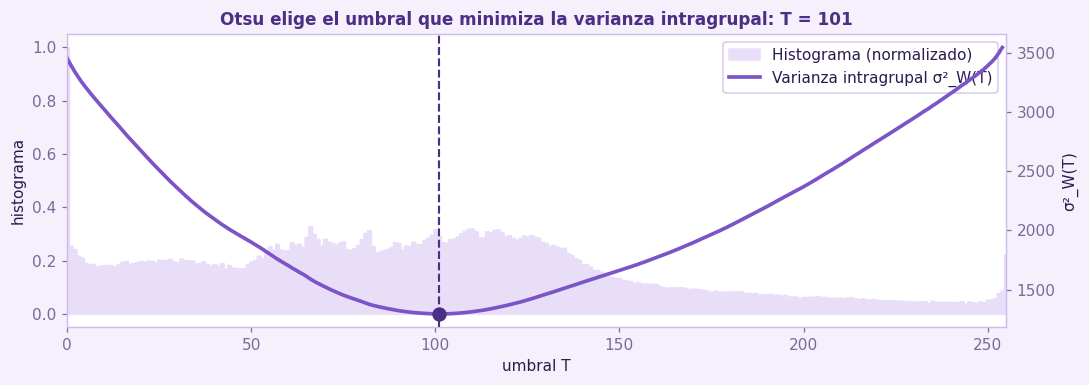

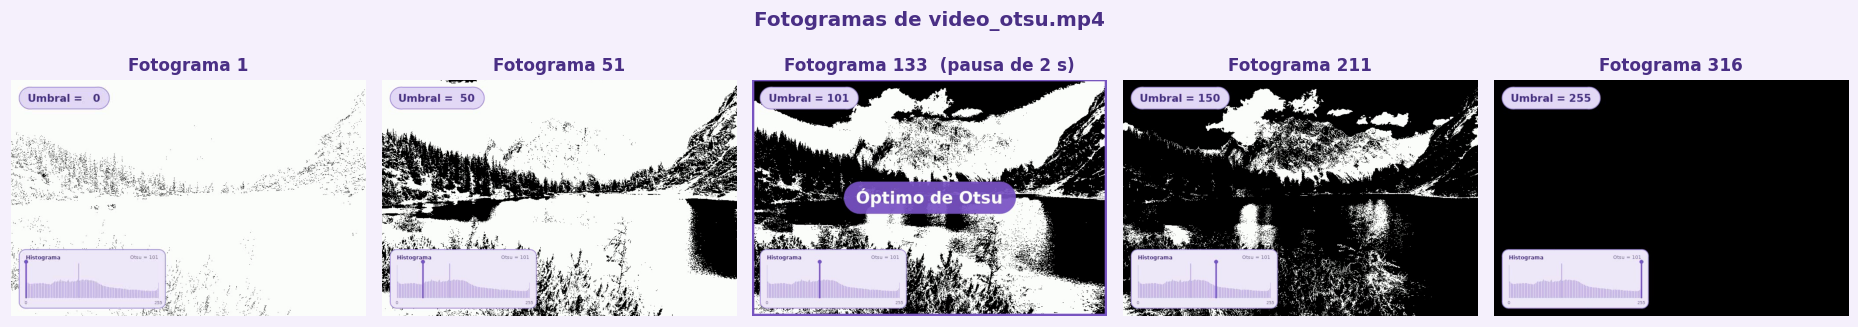

In [12]:
# Comprobación del umbral con la varianza intragrupal (criterio de Otsu) y fotogramas del vídeo
p = hist5 / hist5.sum()
niveles = np.arange(256)
varianza_intra = np.full(256, np.nan)
for t in range(255):
    w_b, w_f = p[:t + 1].sum(), p[t + 1:].sum()               # fondo: <= t, primer plano: > t (como cv.threshold)
    if w_b == 0 or w_f == 0:
        continue
    m_b = (niveles[:t + 1] * p[:t + 1]).sum() / w_b
    m_f = (niveles[t + 1:] * p[t + 1:]).sum() / w_f
    v_b = (((niveles[:t + 1] - m_b) ** 2) * p[:t + 1]).sum() / w_b
    v_f = (((niveles[t + 1:] - m_f) ** 2) * p[t + 1:]).sum() / w_f
    varianza_intra[t] = w_b * v_b + w_f * v_f
t_min = int(np.nanargmin(varianza_intra))
print(f'Mínimo de la varianza intragrupal: T = {t_min}   |   cv.THRESH_OTSU: T = {umbral_otsu}')

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(niveles, hist5 / hist5.max(), step='mid', color=LILA['claro'], label='Histograma (normalizado)')
ax.set_ylabel('histograma'); ax.set_xlabel('umbral T'); ax.set_xlim(0, 255)
ax2 = ax.twinx()
ax2.plot(niveles, varianza_intra, color=LILA['primario'], lw=2.4, label='Varianza intragrupal σ²_W(T)')
ax2.axvline(umbral_otsu, color=LILA['oscuro'], ls='--', lw=1.4)
ax2.scatter([umbral_otsu], [varianza_intra[umbral_otsu]], s=70, color=LILA['oscuro'], zorder=5)
ax2.set_ylabel('σ²_W(T)'); ax2.spines['right'].set_visible(True)
ax.set_title(f'Otsu elige el umbral que minimiza la varianza intragrupal: T = {umbral_otsu}')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right')
fig.tight_layout(); plt.show()

muestras = [0, 50, umbral_otsu, 150, 255]
indices = [m if m <= umbral_otsu else m + SEGUNDOS_PAUSA * FPS_5 for m in muestras]
indices[2] = umbral_otsu + 1 + FPS_5                          # un fotograma dentro de la pausa (con etiqueta)
mostrar(fotogramas_de_video(NOMBRE_VIDEO_5, indices),
        [f'Fotograma {i + 1}' + ('  (pausa de 2 s)' if i == indices[2] else '') for i in indices],
        figsize=(17, 3.2), suptitulo='Fotogramas de video_otsu.mp4')


<div style="background:#E8DEF8;border-left:6px solid #7B54C7;padding:10px 16px;border-radius:8px;margin:6px 0"><span style="color:#4A2F85;font-size:1.25em;font-weight:bold">Ejercicio 6 · Filtro bilateral sobre el ecualizado</span><span style="float:right;color:#7A6A99">0.5 puntos</span></div>


**Qué se pide.** Quitar el ruido de la imagen resultado del ejercicio 4 con un filtro bilateral de diámetro `d = 10` y sigmas 11 y 11, y guardarla como `imagen3_salida.png`.

**Solución.** La entrada es la imagen ecualizada del ejercicio 4 (el ecualizado amplifica el ruido de una imagen tan oscura). `cv.bilateralFilter(imagen, 10, 11, 11)` pondera cada vecino por su cercanía y por lo parecida que sea su intensidad, de modo que suaviza el grano sin cruzar los bordes. Con sigmas tan bajos el filtrado es suave: la diferencia máxima con la entrada es pequeña y los contornos se mantienen, como se ve en el perfil de una fila.


In [13]:
# ---------- Ejercicio 6: filtro bilateral sobre el resultado del ejercicio 4 ----------
# Entrada: imagen3 ecualizada (imagen3_eq). Parámetros del enunciado: d = 10, sigmaColor = 11, sigmaSpace = 11
imagen3_salida = cv.bilateralFilter(imagen3_eq, d=10, sigmaColor=11, sigmaSpace=11)
guardar_imagen('imagen3_salida.png', imagen3_salida)
print(f"Guardada 'imagen3_salida.png' {imagen3_salida.shape} {imagen3_salida.dtype}")


Guardada 'imagen3_salida.png' (500, 500) uint8


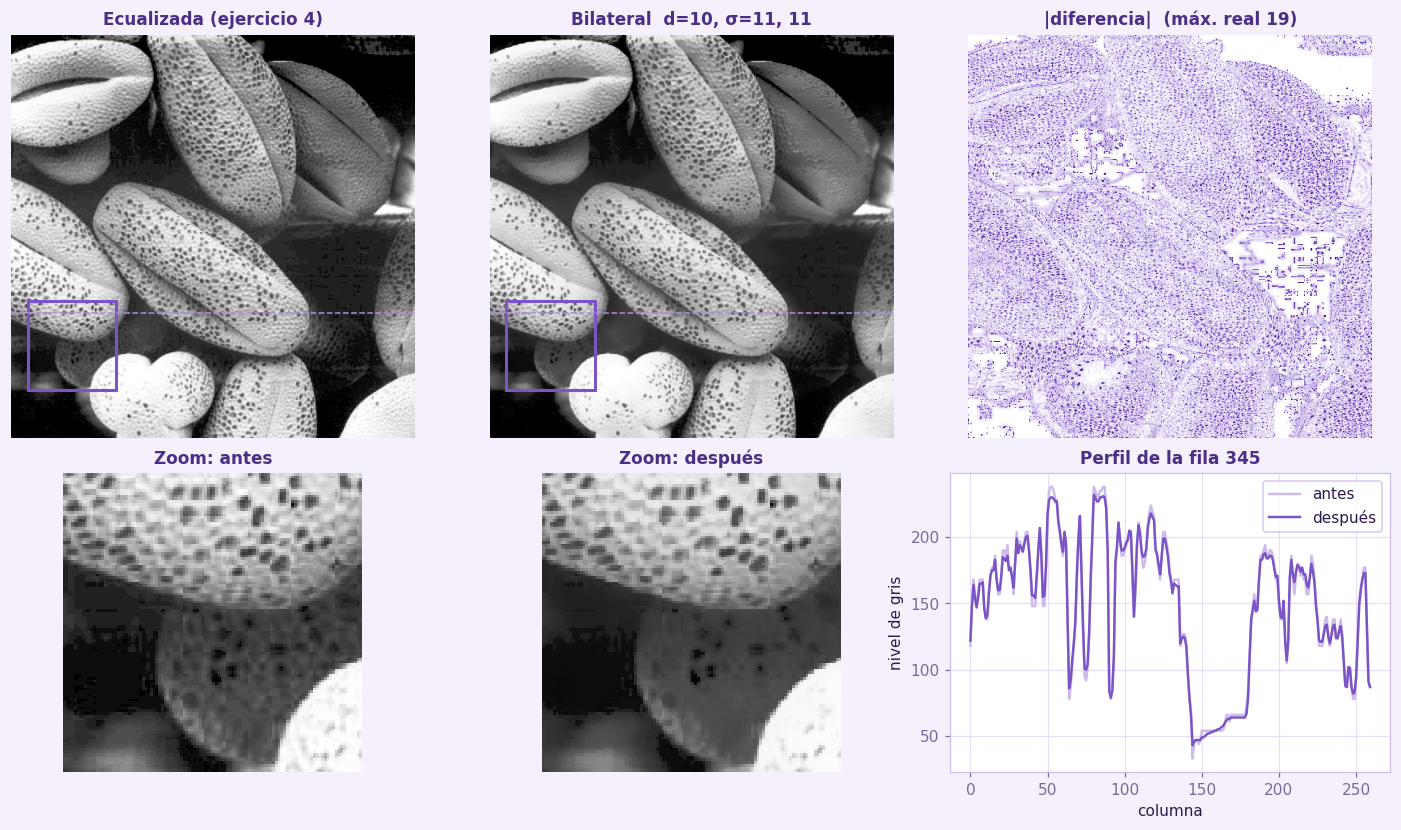

In [14]:
# Antes / después, diferencia y detalle ampliado de una zona con textura
diferencia = cv.absdiff(imagen3_eq, imagen3_salida)
y0, x0, lado = 330, 20, 110                                   # zona ampliada
fila = 345                                                    # fila del perfil (dentro de la zona ampliada)
zoom_a = imagen3_eq[y0:y0 + lado, x0:x0 + lado]
zoom_b = imagen3_salida[y0:y0 + lado, x0:x0 + lado]
vmax_dif = max(float(np.percentile(diferencia, 99.5)), 1.0)

fig = plt.figure(figsize=(13, 7.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1])
for i, (im, t) in enumerate([(imagen3_eq, 'Ecualizada (ejercicio 4)'),
                             (imagen3_salida, 'Bilateral  d=10, σ=11, 11'),
                             (diferencia, f'|diferencia|  (máx. real {diferencia.max()})')]):
    ax = fig.add_subplot(gs[0, i])
    ax.imshow(im, cmap='gray' if i < 2 else CMAP_LILA, vmin=0, vmax=255 if i < 2 else vmax_dif)
    ax.set_title(t); ax.axis('off')
    if i < 2:
        ax.add_patch(mpl.patches.Rectangle((x0, y0), lado, lado, fill=False, ec=LILA['primario'], lw=2))
        ax.axhline(fila, color=LILA['medio'], lw=1, ls='--')
for i, (im, t) in enumerate([(zoom_a, 'Zoom: antes'), (zoom_b, 'Zoom: después')]):
    ax = fig.add_subplot(gs[1, i])
    ax.imshow(im, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(t); ax.axis('off')
ax = fig.add_subplot(gs[1, 2])
ax.plot(imagen3_eq[fila, :260], color=LILA['suave'], lw=1.6, label='antes')
ax.plot(imagen3_salida[fila, :260], color=LILA['primario'], lw=1.6, label='después')
ax.set_title(f'Perfil de la fila {fila}')
ax.set_xlabel('columna'); ax.set_ylabel('nivel de gris'); ax.grid(True); ax.legend()
fig.tight_layout()
plt.show()
